In [19]:
import json
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Get the current working directory
current_dir = Path.cwd()

# If the notebook is running inside the 'notebooks' folder, step up one level to the parent dir
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")


Working directory is already: C:\Users\Matej\Documents\GitHub\MasterThesis


In [20]:
def load_nested_evaluations(eval_dir):
    eval_path = Path(eval_dir)
    all_data = []

    for json_file in eval_path.glob("*.json"):
        with open(json_file, 'r', encoding='utf-8') as f:
            print("Loading data from {}".format(json_file))
            data = json.load(f)

            # Remove the results with most common entities/triplets
            try:
                data["Statistical"]["entities"].pop("top_subjects", None)
                data["Statistical"]["entities"].pop("top_objects", None)
                data["Statistical"]["ontology"].pop("top_schemas", None)
            except KeyError:
                pass # Ignores the error if a file is missing these keys

            all_data.append(data)

    # Flatten the nested JSON
    df = pd.json_normalize(all_data)

    # Just to make the name obvious
    df.rename(columns={"Overview.general.run_name": "Method"}, inplace=True)

    # Only keep the name of the metric
    df.columns = ['.'.join(col.split('.')[-2:]) if '.' in col else col for col in df.columns]

    return df

df = load_nested_evaluations("data/04_reports")
display(df)

Loading data from data\04_reports\few_shot_4examples_temp13.json
Loading data from data\04_reports\half_template_2%_temp13.json
Loading data from data\04_reports\template_2%_temp13.json


,Method,general.dataset_size,general.device_used,general.dataset_path,perplexity.avg_perplexity,perplexity.median_perplexity,grammar.avg_score,grammar.median_score,ontology.total_triplets_extracted,ontology.unique_schemas_used,...,closest_match_similarity.median_closest_match,closest_match_similarity.duplicates_percentage,closest_match_similarity.very_similar_percentage,closest_match_similarity.different_percentage,ngrams.total_3grams,ngrams.unique_3grams,ngrams.3gram_uniqueness_ratio,template_adherence.adherence_percentage,template_adherence.total_checked,template_adherence.total_matched
0,few-shot,610,CUDA,data/03_synthetic/few_shot_4_examples_temp_1_3...,99.181,44.726,0.869,0.962,923,18,...,0.825,11.311,31.803,56.885,6810,3911,57.43,NaN,NaN,NaN
1,half-template,351,CUDA,data/03_synthetic/ontology_2_percent_half_fixe...,49.114,37.045,0.730,0.828,1048,42,...,0.735,0.000,9.117,90.883,11538,7387,64.02,NaN,NaN,NaN
2,template,1840,CUDA,data/03_synthetic/ontology_2_percent_all_fixed...,36.387,27.377,0.865,0.943,1910,18,...,0.818,0.326,36.630,63.043,51466,26837,52.15,99.95,1840.0,1839.0


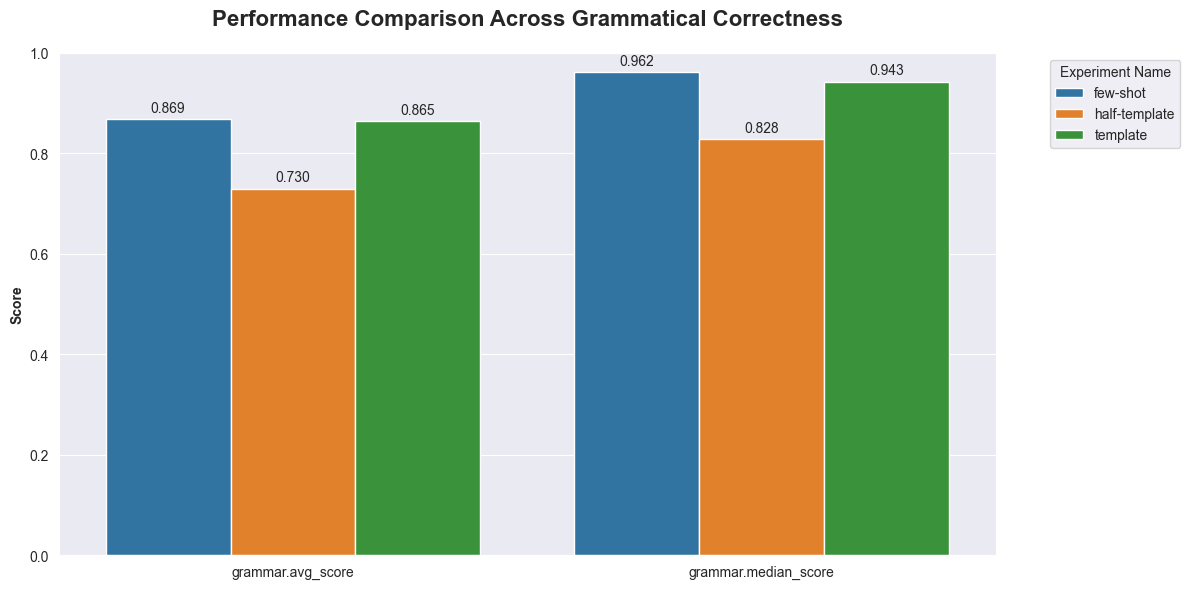

In [21]:
# Grammar plot

df_melted = df.melt(id_vars="Method",
                    value_vars=["grammar.avg_score", "grammar.median_score"],
                    var_name="Metric",
                    value_name="Score")

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_melted, x="Metric", y="Score", hue="Method")

plt.title("Grammatical Correctness", pad=20, fontsize=16, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel("Score", fontweight='bold')
plt.xlabel("")
plt.legend(title="Experiment Name", bbox_to_anchor=(1.05, 1), loc='upper left')

# Add the exact numbers on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10)

plt.tight_layout()
plt.show()

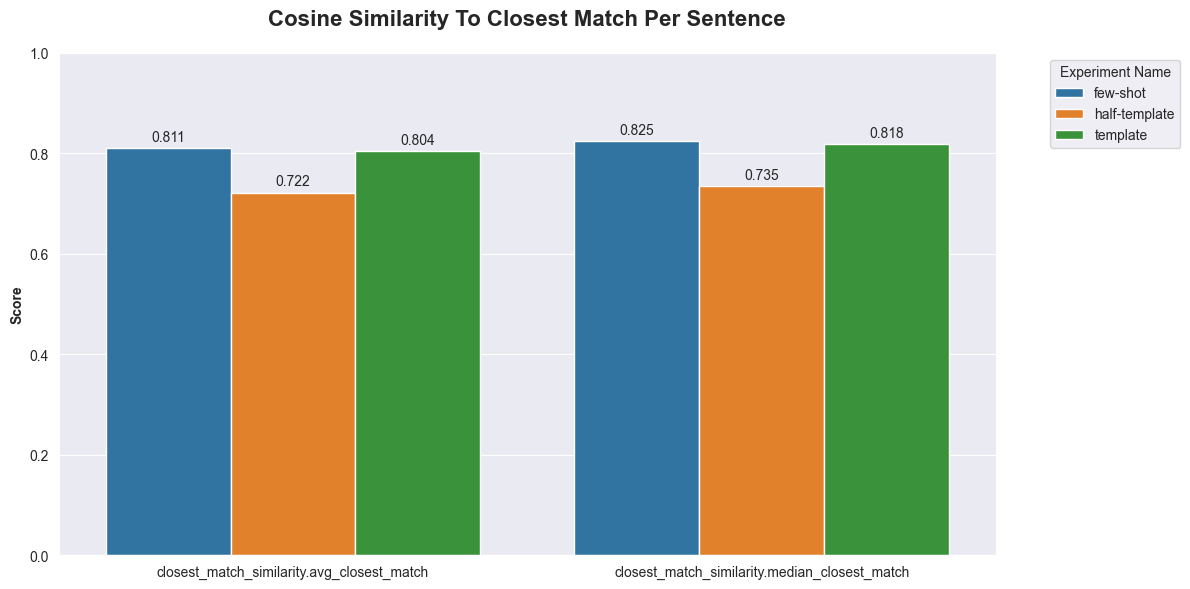

In [25]:
# Closest Match Analysis

df_melted = df.melt(id_vars="Method",
                    value_vars=["closest_match_similarity.avg_closest_match", "closest_match_similarity.median_closest_match"],
                    var_name="Metric",
                    value_name="Score")

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_melted, x="Metric", y="Score", hue="Method")

plt.title("Cosine Similarity To Closest Match Per Sentence", pad=20, fontsize=16, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel("Score", fontweight='bold')
plt.xlabel("")
plt.legend(title="Experiment Name", bbox_to_anchor=(1.05, 1), loc='upper left')

# Add the exact numbers on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10)

plt.tight_layout()
plt.show()

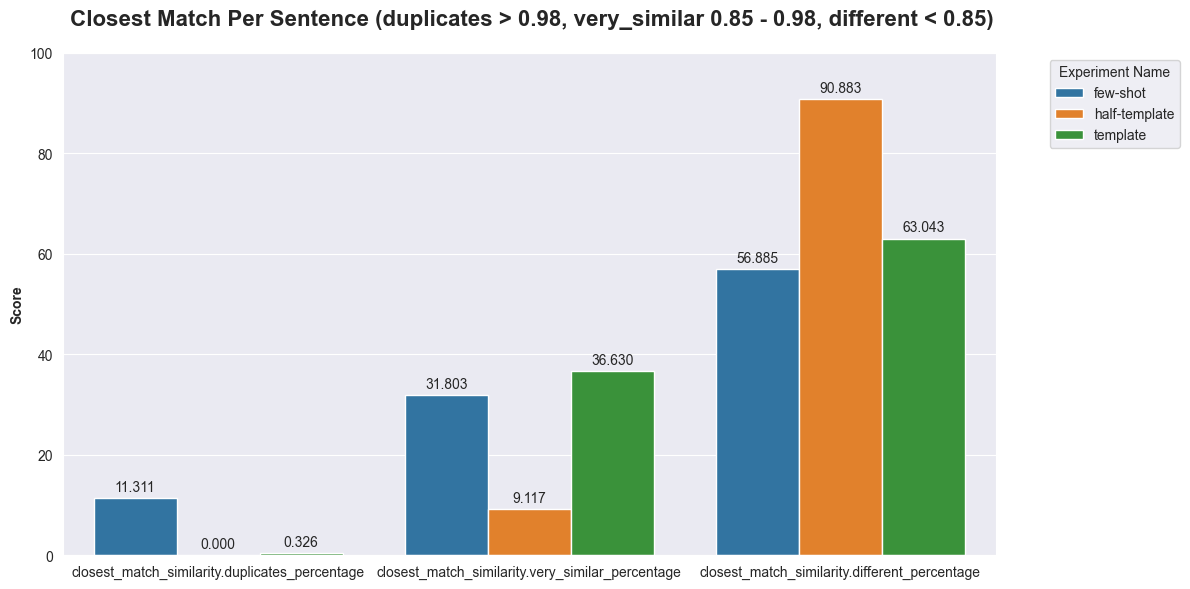

In [26]:
# Closest Match Analysis

df_melted = df.melt(id_vars="Method",
                    value_vars=["closest_match_similarity.duplicates_percentage", "closest_match_similarity.very_similar_percentage", "closest_match_similarity.different_percentage"],
                    var_name="Metric",
                    value_name="Score")

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_melted, x="Metric", y="Score", hue="Method")

plt.title(" Closest Match Per Sentence (duplicates > 0.98, very_similar 0.85 - 0.98, different < 0.85)", pad=20, fontsize=16, fontweight='bold')
plt.ylim(0, 100.0)
plt.ylabel("Score", fontweight='bold')
plt.xlabel("")
plt.legend(title="Experiment Name", bbox_to_anchor=(1.05, 1), loc='upper left')

# Add the exact numbers on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10)

plt.tight_layout()
plt.show()